In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

orders_df = pd.read_csv("store_orders.csv")
customers_df = pd.read_csv("store_customers.csv")

con = sqlite3.connect("store.db")
orders_df.to_sql("orders", con, if_exists="replace", index=False)
customers_df.to_sql("customers", con, if_exists="replace", index=False)

pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,orders
1,customers


In [3]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [4]:
pd.read_sql("""
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC
""", con).head(10)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
5,5113,4,headset,electronics,286.65,2026-05-15
6,5034,29,headset,electronics,286.36,2026-05-14
7,5149,8,headset,electronics,286.30,2026-05-05
8,5004,17,monitor,electronics,284.80,2026-05-10
9,5174,11,headset,electronics,277.24,2026-05-26


In [5]:
pd.read_sql("""
SELECT category,
COUNT(*) AS n,
ROUND(AVG(amount), 2) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC
""", con)

,category,n,avg_amount
0,electronics,60,190.57
1,furniture,46,146.25
2,office,51,30.13
3,snacks,43,14.62


In [6]:
city_spend = pd.read_sql("""
SELECT c.city,
ROUND(SUM(o.amount), 2) AS total_spend
FROM orders AS o
JOIN customers AS c
ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
""", con)
city_spend

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [7]:
n_orders = pd.read_sql("SELECT COUNT(*) AS n FROM orders", con)["n"][0]
n_joined = pd.read_sql("""
SELECT COUNT(*) AS n
FROM orders AS o
JOIN customers AS c ON o.customer_id = c.customer_id
""", con)["n"][0]
print(f"orders rows: {n_orders} | joined rows: {n_joined} | difference: {n_orders - n_joined}")

orders rows: 200 | joined rows: 195 | difference: 5


In [ ]:
#`orders` has 200 rows but the join produced only 195. 
#The missing 5 are  orders whose `customer_id` matches no row in `customers`.
#An INNER JOIN keeps only rows with a match on both sides, so those orders are dropped from the city totals.

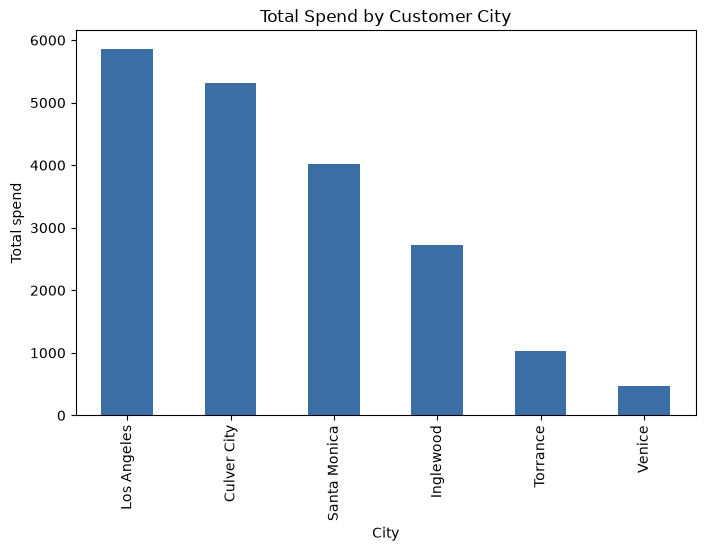

In [10]:
ax = city_spend.plot(kind="bar", x="city", y="total_spend", legend=False,
figsize=(8, 5), color="#3b6ea5")
ax.set_title("Total Spend by Customer City")
ax.set_xlabel("City")
ax.set_ylabel("Total spend")
plt.show()

In [11]:
#WHich 5 customers spend the most in total, and in what city are they in?
pd.read_sql("""
SELECT c.customer_id,
c.name,
c.city,
COUNT(*) AS n_orders,
ROUND(SUM(o.amount), 2) AS total_spend
FROM orders AS o
JOIN customers AS c ON o.customer_id = c.customer_id
GROUP BY c.customer_id, c.name, c.city
ORDER BY total_spend DESC
LIMIT 5
""", con)

,customer_id,name,city,n_orders,total_spend
0,29,Iris Ali,Culver City,7,1222.96
1,30,Jon Brooks,Los Angeles,8,1177.50
2,9,Iris Ali,Inglewood,8,1091.49
3,13,Marco Nguyen,Los Angeles,8,978.99
4,11,Kai Lopez,Los Angeles,5,955.14


In [12]:
#The top spender is customer 29, Iris Ali, Culver City with $1,222.96 over 7 orders,
#followed by Jon Brooks from Los Angeles with $1,177.50. 
#There are two different customers both named Iris Ali,so I grouped by `customer_id` rather than by name.

In [ ]:
#I would take away the names and any other personal identifiers.
#How much they spend by their city does not reveal enough information to indentify someone.